# Exercise 6 — Astrometry in a crowded field

*Covers notebooks 06. Difficulty: ★★★★☆*

At 16.9 mas per pixel the WCC resolves fields that seeing blends. How precisely are star positions recovered from a single frame of Baade's Window, as a function of magnitude and exposure time?

*Renders 2048 px frames: ~10 s each, ~1 GB. Restart the kernel when done.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.visualization import simple_norm
from wcc_etc import plot_image_mpl
from wcc_sim import simulate_field
from wcc_sim.catalog import query_gaia
from wcc_phot import run_photometry
from wcc_phot.centroid import centroid_stars

### 6.1 — Baade's Window

Render a 10 s zwo:r frame of Baade's Window, (RA, Dec) = (270.9°, -30.03°), on a 2048 px subarray
(the Gaia query is cached; use `cache_dir="gaia_cache"` and `seed=7`). How many stars are in the
frame, how many are saturated, and how bright is the brightest? Show the frame with the saturated
stars marked.

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


206 stars in frame, 24 saturated, brightest G = 11.3


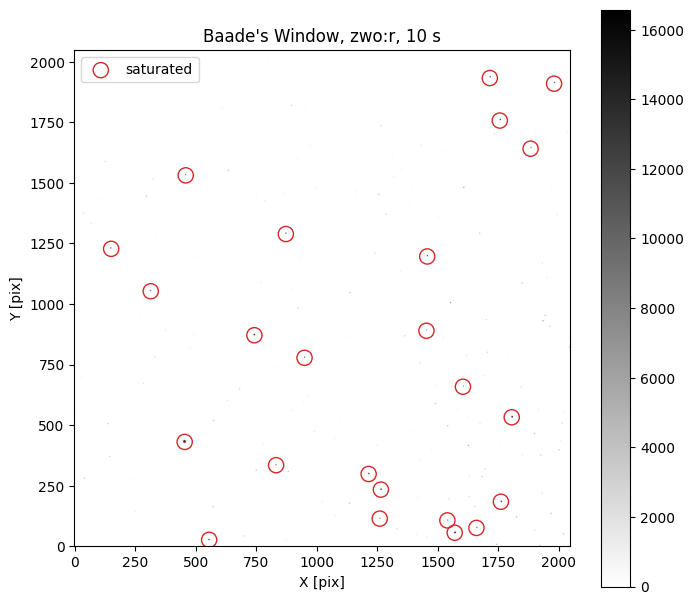

In [2]:
RA, DEC = 270.9, -30.03
field = simulate_field(RA, DEC, sensorfilter="zwo:r", focus=0, exptime=10, seed=7, shape=(2048, 2048), cache_dir="gaia_cache")
PLATE = field.params["plate_scale_mas"]
c = field.catalog
inn = np.asarray(c["in_image"], bool); sat = np.asarray(c["saturated"], bool)
print(f"{inn.sum()} stars in frame, {(inn & sat).sum()} saturated, brightest G = {c['phot_g_mean_mag'][inn].min():.1f}")
fig, ax = plt.subplots(figsize=(8, 7.5))
plot_image_mpl(image_e=field.image_e, saturation_mask=field.saturation_mask, pixel_scale_mas=PLATE, show_saturation=True, stretch="asinh", cmap="gray_r", ax=ax)
ax.scatter(c["x"][inn & sat], c["y"][inn & sat], s=120, facecolors="none", edgecolors="C3", label="saturated")
ax.legend(); ax.set_title("Baade's Window, zwo:r, 10 s")
plt.show()

### 6.2 — A cell with a bug

The cell below recentroids every unsaturated star and prints the scatter against the truth
catalogue. It runs without error, but the numbers it prints are wrong by a constant factor.
Find the bug (with or without Jupyter AI), fix it, and keep going. Is 0.03 "mas" plausible for a
2.4 px FWHM PSF?

In [3]:
use = inn & ~sat & (c["x"] > 20) & (c["x"] < 2027) & (c["y"] > 20) & (c["y"] < 2027)
x, y, flags = centroid_stars(field, c["x"][use], c["y"][use], box=15)
good = flags == 0
dx = (x - c["x"][use])[good]; dy = (y - c["y"][use])[good]            # BUG: these are pixels, not mas
print(f"{good.sum()} stars: scatter sigma_x = {dx.std():.3f}, sigma_y = {dy.std():.3f} mas")

175 stars: scatter sigma_x = 0.030, sigma_y = 0.032 mas


In [4]:
dx = (x - c["x"][use])[good] * PLATE; dy = (y - c["y"][use])[good] * PLATE     # fixed: pixels -> mas
print(f"{good.sum()} stars: scatter sigma_x = {dx.std():.2f}, sigma_y = {dy.std():.2f} mas; mean offset ({dx.mean():+.2f}, {dy.mean():+.2f}) mas")

175 stars: scatter sigma_x = 0.51, sigma_y = 0.54 mas; mean offset (+0.03, +0.01) mas


### 6.3 — Precision versus magnitude

Plot the radial residual of each star against its Gaia G, and the per-coordinate scatter in 1 mag
bins. Add a line at 0.1 px.

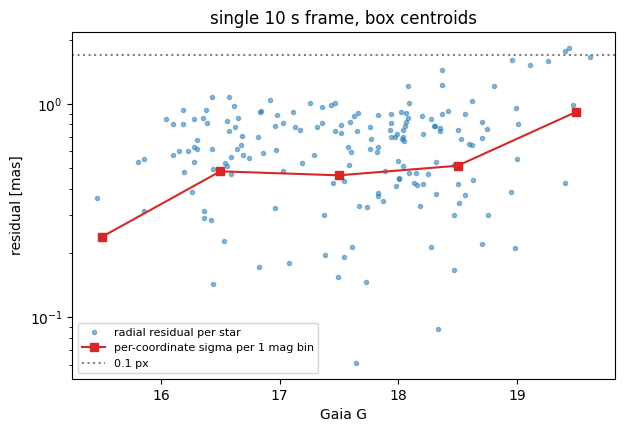

In [5]:
g = np.asarray(c["phot_g_mean_mag"][use])[good]; res = np.hypot(dx, dy)
edges = np.arange(13, 21.5, 1); mid = 0.5 * (edges[1:] + edges[:-1])
sig = [0.5 * (dx[m].std() + dy[m].std()) if m.sum() > 2 else np.nan for m in [(g >= a) & (g < b) for a, b in zip(edges[:-1], edges[1:])]]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(g, res, ".", alpha=0.5, label="radial residual per star")
ax.plot(mid, sig, "s-", color="C3", label="per-coordinate sigma per 1 mag bin")
ax.axhline(PLATE / 10, color="0.5", ls=":", label="0.1 px")
ax.set(xlabel="Gaia G", ylabel="residual [mas]", title="single 10 s frame, box centroids"); ax.legend(fontsize=8)
plt.show()

> ✏️ **Before you run the next cell:** from 2 s to 20 s exposures, does the centroid scatter of 17 < G < 19 stars fall as t^-1/2 all the way? Write your guess down (or put it in the room poll), then run.

### 6.4 — Precision versus exposure time

For exposures of 2, 5, 10 and 20 s (same seed), compute the pooled per-coordinate scatter of stars
with 17 < G < 19 and plot it against exposure time with a $t^{-1/2}$ reference. What limits the
precision at the long end?

  2 s: 112 stars, per-coordinate sigma 1.15 mas


  5 s: 112 stars, per-coordinate sigma 0.63 mas


 10 s: 112 stars, per-coordinate sigma 0.49 mas


 20 s: 112 stars, per-coordinate sigma 0.48 mas


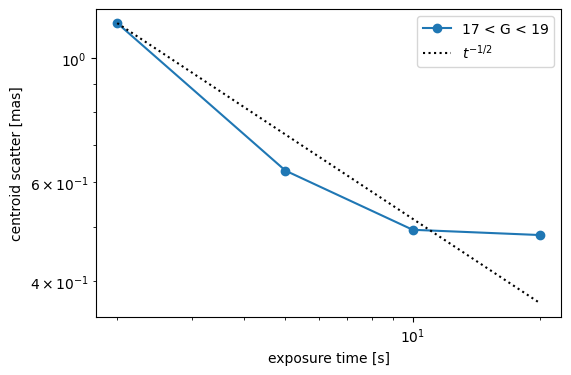

In [6]:
times = [2, 5, 10, 20]
sig_t = []
for t in times:
    f = simulate_field(RA, DEC, sensorfilter="zwo:r", focus=0, exptime=t, seed=7, shape=(2048, 2048), cache_dir="gaia_cache")
    ct = f.catalog
    sel = (np.asarray(ct["in_image"], bool) & ~np.asarray(ct["saturated"], bool) & (ct["phot_g_mean_mag"] > 17) & (ct["phot_g_mean_mag"] < 19)
           & (ct["x"] > 20) & (ct["x"] < 2027) & (ct["y"] > 20) & (ct["y"] < 2027))
    xt, yt, ft = centroid_stars(f, ct["x"][sel], ct["y"][sel], box=15)
    gd = ft == 0
    d = np.concatenate([(xt - ct["x"][sel])[gd], (yt - ct["y"][sel])[gd]]) * PLATE
    sig_t.append(d.std())
    print(f"{t:3d} s: {sel.sum()} stars, per-coordinate sigma {sig_t[-1]:.2f} mas")
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(times, sig_t, "o-", label="17 < G < 19")
ax.loglog(times, sig_t[0] * np.sqrt(times[0] / np.array(times)), "k:", label="$t^{-1/2}$")
ax.set(xlabel="exposure time [s]", ylabel="centroid scatter [mas]"); ax.legend()
plt.show()
# Crowding and the fixed centroid box (neighbours bias the centre of mass) flatten the curve; PSF fitting would do better.

> 🤖 **Ask Jupyter AI:** *The dithered-stack version of this: render five frames shifted by 40 pixels in RA and Dec, register them on the CAT positions with integer shifts (no np.roll: it wraps the edges), co-add, and check that the SNR of a faint star grows as sqrt(N).*
>
> Ask it to inject point sources at G = 21 to 27 first so there is something faint to measure.

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/wcc-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*